# Baseline Evaluation of DBPs using Gemini Flash 2.5

This notebook evaluates ~700 Disinfection By-Products (DBPs) using the Gemini Flash 2.5 model directly (baseline), without the agentic workflow.


In [1]:
import os
import pandas as pd
from dotenv import load_dotenv
from tqdm import tqdm
from typing import Optional
from pydantic import Field, SecretStr
from langchain_core.utils.utils import secret_from_env
from langchain_openai import ChatOpenAI

load_dotenv()

# Define ChatOpenRouter class as in hmdb_test_llm.ipynb
class ChatOpenRouter(ChatOpenAI):
    openai_api_key: Optional[SecretStr] = Field(
        alias="api_key", default_factory=secret_from_env("OPENROUTER_API_KEY", default=None)
    )
    @property
    def lc_secrets(self) -> dict[str, str]:
        return {"openai_api_key": "OPENROUTER_API_KEY"}

    def __init__(self,
                 openai_api_key: Optional[str] = None,
                 **kwargs):
        openai_api_key = openai_api_key or os.environ.get("OPENROUTER_API_KEY")
        super().__init__(base_url="https://openrouter.ai/api/v1", openai_api_key=openai_api_key, **kwargs)

# Initialize the model
# Using the model name as specified in the user request/context
model = ChatOpenRouter(model_name="google/gemini-2.5-flash", temperature=0.0)

print("Model initialized.")


/home/chen/GNPS_SIM/agent/db_form_agent_system/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model initialized.


In [2]:
# Load Data
file_path = "../es4c13900_si_001.xlsx"
if os.path.exists(file_path):
    df = pd.read_excel(file_path, sheet_name='TableS1_716 Confirmed DBPs', header=1)
    
    # Clean up column names
    df.columns = [c.strip() for c in df.columns]
    
    # Filter out NaNs in IUPAC name
    df_clean = df.dropna(subset=['IUPAC name'])
    
    print(f"Total rows loaded: {len(df)}")
    print(f"Rows after cleaning: {len(df_clean)}")
    print(df_clean[['IUPAC name', 'Preferred DBP name']].head())
else:
    print(f"File not found: {file_path}")
    df_clean = pd.DataFrame()


Total rows loaded: 716
Rows after cleaning: 687
                                          IUPAC name  \
0                        2,2,2-trichloroacetaldehyde   
1  2,6-Dibromo-4-[1-[3,5-dibromo-4-(2,6-dibromo-4...   
2  (1S,2R,3R,4S,5R,8R,9S,10S,11R,12R,14R)-11-[(2S...   
4         L-Alanine, N-(3,5-diiodo-L-tyrosyl)- (9CI)   
5                    1,3,6,8-Tetrabromo-9H-carbazole   

                                  Preferred DBP name  
0  Chloral (Trichloroethanal; Trichloroacetaldehy...  
1  2,6-Dibromo-4-(2-(3,5-Dibromo-4-(2,6-Dibromo-4...  
2                       Anhydroerythromycin (E-DBP1)  
4      3,5-Diiodo-Tyrosylalanine  (3,5-Di-I-Tyr-Ala)  
5                        1,3,6,8-Tetrabromocarbazole  


In [ ]:

def model_invoke(compound_name: str) -> str:
    query = f"According to the following definition: A disinfection byproduct (DBP) is a chemical compound that is formed incidentally by the reaction of a disinfectant with organic and inorganic matter present in water, wastewater, or other matrices. To be considered 'experimentally confirmed', there must be clear evidence from a peer-reviewed study demonstrating its formation during a disinfection process and its chemical identification. Is the compound '{compound_name}' a confirmed DBP? Answer: 'Confirmed DBP' or 'Not Confirmed DBP'"
    response_message = model.invoke(query)
    return response_message.content.strip()

In [5]:
# test on the dataset
results = []
for compound in tqdm(df_clean['IUPAC name'], desc="Processing compounds"):
    res = model_invoke(compound)
    results.append(res)

df_clean['Model Prediction'] = results
output_file = "dbp_gemini_flash_2_5_results.xlsx"
df_clean.to_excel(output_file, index=False)
print(f"Results saved to {output_file}")

Processing compounds: 100%|██████████| 687/687 [15:53<00:00,  1.39s/it]  

Results saved to dbp_gemini_flash_2_5_results.xlsx



/tmp/ipykernel_5050/1112813400.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['Model Prediction'] = results


In [2]:
# load file "dbp_gemini_flash_2_5_results.xlsx"
df_clean = pd.read_excel("dbp_gemini_flash_2_5_results.xlsx")

In [3]:
df_clean

,IUPAC name,CAS,Molecular Formula,Monoisotopic Mass,Molecular Weight,INCHIKEY,SMILES,Preferred DBP name,Water Source,Disinfection,Carbon Frames,Structural Category,Functional Group Category,Halogen-Based Category,Common-Used Category,Literature on the Confirmation of DBPs Using Standards,Model Prediction
0,"2,2,2-trichloroacetaldehyde",75-87-6,C2HCl3O/C2H3Cl3O2,145.909298,147.38/165.4,HFFLGKNGCAIQMO-UHFFFAOYSA-N,O=CC(Cl)(Cl)Cl,Chloral (Trichloroethanal; Trichloroacetaldehy...,Real drinking water;\nSwimming pool water;\nSp...,Chlorination;\nChloramination;\nChlorine dioxi...,C-DBP,Aliphatic,Aldehydes,Cl-DBP,Haloacetaldehydes (HAcAL),"1977 (Environ. Sci. Technol. 1977, 11, 5, 478–...",Confirmed DBP
1,"2,6-Dibromo-4-[1-[3,5-dibromo-4-(2,6-dibromo-4...",1379587-32-2,C21H14Br6O3,NaN,793.8,IMWNKTURUJDAJT-UHFFFAOYSA-N,BrC=1C=C(C=C(Br)C1O)C(C2=CC(Br)=C(OC3=C(Br)C=C...,"2,6-Dibromo-4-(2-(3,5-Dibromo-4-(2,6-Dibromo-4...",Simulated water (of Simulated water of source ...,Chlorination,C-DBP,Aromatic,Phenols,Br-DBP,Halophenols (HP),"2016 (Environ. Sci. Technol. 2016, 50, 9608−96...",Not Confirmed DBP
2,"(1S,2R,3R,4S,5R,8R,9S,10S,11R,12R,14R)-11-[(2S...",23893-13-2,C37H65NO12,715.450677,715.92,YKAVHPRGGAUFDN-JTQLBUQXSA-N,O=C1OC(CC)C2(OC3(OC(C)(CC3C)C(OC4OC(C)CC(N(C)C...,Anhydroerythromycin (E-DBP1),Simulated water (with model chemicals);,Chlorine dioxide disinfection,N-DBP,Alicyclic,Esters,Non-halo,Other (TPs of Erythromycin),"2019 (Environ. Sci. Pollut. Res., 2019, 26, 28...",Not Confirmed DBP
3,"L-Alanine, N-(3,5-diiodo-L-tyrosyl)- (9CI)",42934-95-2,C12H14I2N2O4,NaN,504.06,DWCKYSMGNOOVJD-CDUCUWFYSA-N,O=C(O)C(NC(=O)C(N)CC1=CC(I)=C(O)C(I)=C1)C,"3,5-Diiodo-Tyrosylalanine (3,5-Di-I-Tyr-Ala)",Real drinking water (tap water);,Chloramination,N-DBP,Aromatic,Amines,I-DBP,Halo-Dipeptides (HDP),"2018 (Environ. Sci. Technol. 2018, 52, 4218−42...",Not Confirmed DBP
4,"1,3,6,8-Tetrabromo-9H-carbazole",55119-09-0,C12H5Br4N,478.715551,482.79,FNHISDQCWYSMTO-UHFFFAOYSA-N,BrC1=CC2=C(NC3=C2C=C(Br)C=C3Br)C(Br)=C1,"1,3,6,8-Tetrabromocarbazole",Real drinking water (tap water);\nSimulated wa...,Chlorination;\nChloramination;,N-DBP,Aromatic,Other (Carbazoles),Br-DBP,Halocarbazoles (HCBz),"2019 (Water Res., 2019, 159, 252-261);",Not Confirmed DBP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
682,Chloromethane,74-87-3,CH3Cl,49.992328,50.49,NEHMKBQYUWJMIP-UHFFFAOYSA-N,CCl,Chloromethane (Methyl Chloride),Real drinking water;,Chlorination,C-DBP,Aliphatic,Alkanes,Cl-DBP,Halomethanes (HM),1976 (Identification and Analysis of Organic P...,Not Confirmed DBP
683,Formic acid,64-18-6,CH2O2,46.005479,46.025,BDAGIHXWWSANSR-UHFFFAOYSA-N,OC=O,Formic Acid,"Simulated water (with ozonated benzaldehylde,p...",Ozonation,C-DBP,Aliphatic,Carboxylic Acids,Non-halo,Monocarboxylic acids,"1981 (Ozone Sci. Eng., 1981, 3, 33-48);\n1983 ...",Not Confirmed DBP
684,Acetaldehyde,75-07-0,C2H4O,44.026215,44.05,IKHGUXGNUITLKF-UHFFFAOYSA-N,CC=O,Acetaldehyde (Ethanal),Real drinking water;,Chlorination;\nChloramination;\nOzonation;\nCh...,C-DBP,Aliphatic,Aldehydes,Non-halo,Aliphatic aldehydes,1976 (Identification and Analysis of Organic P...,Confirmed DBP
685,Hydrogen peroxide,7722-84-1,H2O2,34.005479,34.015,MHAJPDPJQMAIIY-UHFFFAOYSA-N,OO,Hydrogen Peroxide (H2O2),Real drinking water;,Ozonation,Inorganic DBP,Inorganic,Other (Peroxides),Inorganic DBP,Other (Peroxides),"1983 (Ozone Sci. Eng. 1983, 5 151-170);",Not Confirmed DBP


In [4]:
# Create a mask for values NOT in the allowed list (case-sensitive)
mask = ~df_clean['Model Prediction'].isin(['Not Confirmed DBP', 'Confirmed DBP'])

# Replace the values that match the mask with 'unclear'
df_clean.loc[mask, 'Model Prediction'] = 'unclear'


Model Prediction
Not Confirmed DBP    579
Confirmed DBP         69
unclear               39
Name: count, dtype: int64


/tmp/ipykernel_7385/1124933586.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=prediction_counts.index, y=prediction_counts.values,


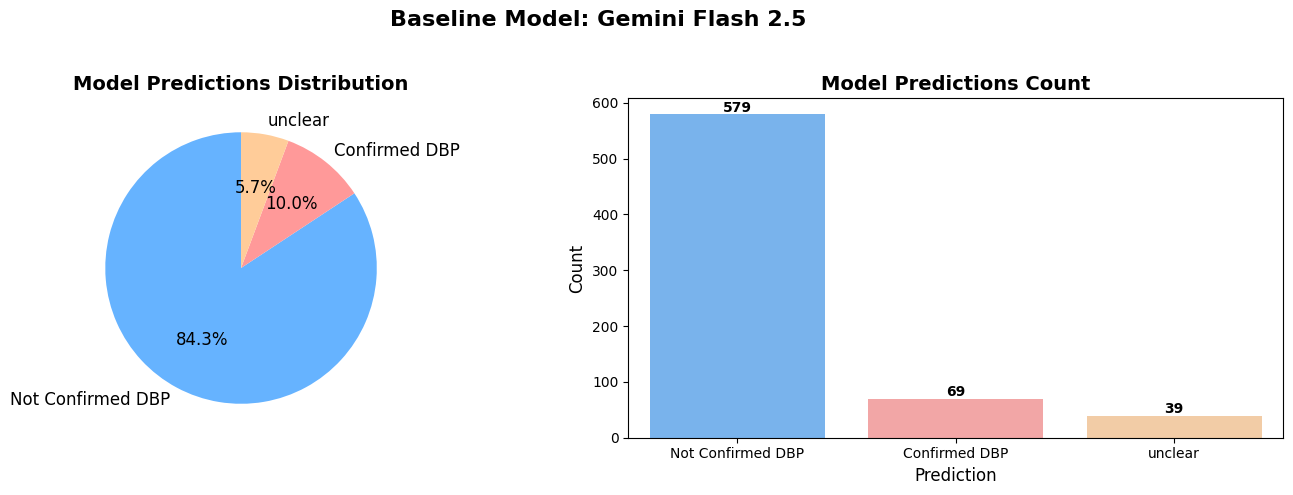


Total compounds evaluated: 687
Confirmed DBPs: 69 (10.0%)
Not Confirmed DBPs: 579 (84.3%)
Unclear: 39 (5.7%)


In [5]:
# plot the model prediction ratio
import matplotlib.pyplot as plt
import seaborn as sns

# Count predictions
prediction_counts = df_clean['Model Prediction'].value_counts()
print(prediction_counts)

# Create figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ----- Add main title -----
fig.suptitle("Baseline Model: Gemini Flash 2.5", fontsize=16, fontweight='bold')

# Pie chart
colors = ['#66b3ff', '#ff9999', '#ffcc99']
axes[0].pie(prediction_counts.values, labels=prediction_counts.index, autopct='%1.1f%%',
            colors=colors, startangle=90, textprops={'fontsize': 12})
axes[0].set_title('Model Predictions Distribution', fontsize=14, fontweight='bold')

# Bar chart
sns.barplot(x=prediction_counts.index, y=prediction_counts.values, 
            palette=['#66b3ff', '#ff9999', '#ffcc99'], ax=axes[1])
axes[1].set_title('Model Predictions Count', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Prediction', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)

# Add value labels on bars
for i, v in enumerate(prediction_counts.values):
    axes[1].text(i, v + 5, str(v), ha='center', fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.95])  # adjust for suptitle
plt.show()

# Print summary statistics
print(f"\nTotal compounds evaluated: {len(df_clean)}")
print(f"Confirmed DBPs: {prediction_counts.get('Confirmed DBP', 0)} ({prediction_counts.get('Confirmed DBP', 0)/len(df_clean)*100:.1f}%)")
print(f"Not Confirmed DBPs: {prediction_counts.get('Not Confirmed DBP', 0)} ({prediction_counts.get('Not Confirmed DBP', 0)/len(df_clean)*100:.1f}%)")
print(f"Unclear: {prediction_counts.get('unclear', 0)} ({prediction_counts.get('unclear', 0)/len(df_clean)*100:.1f}%)")


In [ ]:
# load /home/chen/GNPS_SIM/agent/db_form_agent_system/notebooks/dbp_evaluation_sample_results.csv
# select same iupac name and compare with baseline results

df_sample = pd.read_csv('/home/chen/GNPS_SIM/agent/db_form_agent_system/notebooks/dbp_evaluation_sample_results.csv')



In [10]:
df_sample

,compound,agent_claim,predicted_normalized,session_dir
0,5-Bromo-6-chloropyridin-3-ol,Not Confirmed DBP,No,../searching_results/dbp_eval_8e576327-8567-42...
1,3-Methylbutanal,Unclear,Unclear,../searching_results/dbp_eval_798483e8-60b5-4e...
2,Undecanedioic acid,Not Confirmed DBP,No,../searching_results/dbp_eval_977fa997-9bbc-4b...
3,"2-Chloronaphthalene-1,4-dione",Not Confirmed DBP,No,../searching_results/dbp_eval_a6042fd2-9a45-45...
4,Bromo(trichloro)methane,Unclear,Unclear,../searching_results/dbp_eval_49ab5bfd-d514-47...
5,Dibromo(chloro)acetonitrile,Confirmed DBP,Yes,../searching_results/dbp_eval_8358c33b-aada-48...
6,3-Oxobutanoic acid,Not Confirmed DBP,No,../searching_results/dbp_eval_600c6c21-abe9-4a...
7,"6-Chloro-1,2,3,4-tetrahydro-1,1,2,4,4,7-hexame...",Not Confirmed DBP,No,../searching_results/dbp_eval_3dbe1cc9-d74b-41...
8,"2,3,4-Trimethylcyclopent-2-en-1-one",Not Confirmed DBP,No,../searching_results/dbp_eval_2a132c7d-e0c5-4c...
9,"5-Chloro-5,10-dihydrophenazine",Not Confirmed DBP,No,../searching_results/dbp_eval_54ca05df-f602-46...


In [11]:
# load sample results and compare with baseline
df_sample = pd.read_csv('/home/chen/GNPS_SIM/agent/db_form_agent_system/notebooks/dbp_evaluation_sample_results.csv')

# merge df_sample.compound with df_clean['IUPAC name']
merged = df_sample.merge(
    df_clean[['IUPAC name', 'Model Prediction']],
    left_on='compound',
    right_on='IUPAC name',
    how='left',
    suffixes=('', '_Baseline')
)

print(f"Rows merged: {len(merged)}")
print("Rows with no baseline match:", merged['Model Prediction'].isna().sum())

merged.head()

Rows merged: 30
Rows with no baseline match: 0


,compound,agent_claim,predicted_normalized,session_dir,IUPAC name,Model Prediction
0,5-Bromo-6-chloropyridin-3-ol,Not Confirmed DBP,No,../searching_results/dbp_eval_8e576327-8567-42...,5-Bromo-6-chloropyridin-3-ol,Not Confirmed DBP
1,3-Methylbutanal,Unclear,Unclear,../searching_results/dbp_eval_798483e8-60b5-4e...,3-Methylbutanal,Not Confirmed DBP
2,Undecanedioic acid,Not Confirmed DBP,No,../searching_results/dbp_eval_977fa997-9bbc-4b...,Undecanedioic acid,Not Confirmed DBP
3,"2-Chloronaphthalene-1,4-dione",Not Confirmed DBP,No,../searching_results/dbp_eval_a6042fd2-9a45-45...,"2-Chloronaphthalene-1,4-dione",Not Confirmed DBP
4,Bromo(trichloro)methane,Unclear,Unclear,../searching_results/dbp_eval_49ab5bfd-d514-47...,Bromo(trichloro)methane,Not Confirmed DBP


In [13]:
merged[['compound', 'agent_claim', 'Model Prediction']]

,compound,agent_claim,Model Prediction
0,5-Bromo-6-chloropyridin-3-ol,Not Confirmed DBP,Not Confirmed DBP
1,3-Methylbutanal,Unclear,Not Confirmed DBP
2,Undecanedioic acid,Not Confirmed DBP,Not Confirmed DBP
3,"2-Chloronaphthalene-1,4-dione",Not Confirmed DBP,Not Confirmed DBP
4,Bromo(trichloro)methane,Unclear,Not Confirmed DBP
5,Dibromo(chloro)acetonitrile,Confirmed DBP,Confirmed DBP
6,3-Oxobutanoic acid,Not Confirmed DBP,Not Confirmed DBP
7,"6-Chloro-1,2,3,4-tetrahydro-1,1,2,4,4,7-hexame...",Not Confirmed DBP,Not Confirmed DBP
8,"2,3,4-Trimethylcyclopent-2-en-1-one",Not Confirmed DBP,Not Confirmed DBP
9,"5-Chloro-5,10-dihydrophenazine",Not Confirmed DBP,Not Confirmed DBP
